
# 📘 Cats vs Dogs Classification using CNN

# 1. Title



## Project ID: PRAICP-1011

## Business Case:
Develop a machine learning model that can classify images as cat or dog.

## Objective:
Build a CNN model to classify images into two categories: Cats and Dogs.

## Dataset:
Images of Cats and Dogs (2 folders)

# 2. Import Libraries

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras import layers, models

# 3. Extract Dataset







In [2]:
import zipfile

zip_path = "/content/Cats-Dogs-2.zip"
extract_path = "data/"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extraction done!")

Extraction done!


# 4. Set Dataset Path

In [5]:
import os

# Let's inspect the extracted folder structure inside 'data'
base_path = "data"
if os.path.exists(base_path):
    contents = os.listdir(base_path)
    print(f"Contents of '{base_path}':", contents)

    # Attempt to automatically find the correct subfolder
    subfolders = [f for f in contents if os.path.isdir(os.path.join(base_path, f))]
    if subfolders:
        data_dir = os.path.join(base_path, subfolders[0])
        print(f"Setting data_dir to: '{data_dir}'")
        print("Subfolder contents:", os.listdir(data_dir))
    else:
        data_dir = base_path
        print(f"No subfolders found. Setting data_dir to: '{data_dir}'")
else:
    print(f"Error: The base directory '{base_path}' does not exist. Please check if extraction was successful.")

Contents of 'data': ['readme[1].txt', 'PetImages', 'MSR-LA - 3467.docx']
Setting data_dir to: 'data/PetImages'
Subfolder contents: ['Cat', 'Dog']


# 5. Data Preprocessing

In [6]:
img_size = (150,150)
batch_size = 32

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

train_data = datagen.flow_from_directory(
    data_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    subset='training'
)

val_data = datagen.flow_from_directory(
    data_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    subset='validation'
)

Found 20000 images belonging to 2 classes.
Found 5000 images belonging to 2 classes.


# 6. Build CNN Model

In [7]:
model = models.Sequential()

model.add(layers.Conv2D(32, (3,3), activation='relu', input_shape=(150,150,3)))
model.add(layers.MaxPooling2D(2,2))

model.add(layers.Conv2D(64, (3,3), activation='relu'))
model.add(layers.MaxPooling2D(2,2))

model.add(layers.Conv2D(128, (3,3), activation='relu'))
model.add(layers.MaxPooling2D(2,2))

model.add(layers.Flatten())
model.add(layers.Dense(128, activation='relu'))
model.add(layers.Dense(1, activation='sigmoid'))

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,735,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,828,481 (18.42 MB)

 Trainable params: 4,828,481 (18.42 MB)

 Non-trainable params: 0 (0.00 B)

# 7. Compile Model

In [8]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# 8. Train Model

In [10]:
from PIL import Image
import os

# Clean corrupted images from the dataset before training
print("Cleaning corrupt and invalid images...")
num_removed = 0

for root, dirs, files in os.walk(data_dir):
    for file in files:
        file_path = os.path.join(root, file)
        # Skip hidden/system files
        if file.startswith('.') or file.lower() == 'thumbs.db':
            try:
                os.remove(file_path)
                num_removed += 1
            except:
                pass
            continue

        # Check if the image is valid
        if file.lower().endswith(('.png', '.jpg', '.jpeg')):
            try:
                with Image.open(file_path) as img:
                    img.verify()  # Verify image integrity
            except (IOError, SyntaxError) as e:
                print(f"Removing corrupted/invalid image: {file_path}")
                try:
                    os.remove(file_path)
                    num_removed += 1
                except Exception as ex:
                    print(f"Could not remove {file_path}: {ex}")

print(f"Cleanup complete. Removed {num_removed} files.")

# Re-initialize the generators to exclude deleted corrupt files
train_data = datagen.flow_from_directory(
    data_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    subset='training'
)

val_data = datagen.flow_from_directory(
    data_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='binary',
    subset='validation'
)

# Start training
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5
)

Cleaning corrupt and invalid images...
Removing corrupted/invalid image: data/PetImages/Cat/666.jpg
Removing corrupted/invalid image: data/PetImages/Dog/11702.jpg


/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


Cleanup complete. Removed 4 files.
Found 20000 images belonging to 2 classes.
Found 4998 images belonging to 2 classes.
Epoch 1/5
146/625 ━━━━━━━━━━━━━━━━━━━━ 10:41 1s/step - accuracy: 0.7370 - loss: 0.5333

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Truncated File Read
  warnings.warn(str(msg))


625/625 ━━━━━━━━━━━━━━━━━━━━ 915s 1s/step - accuracy: 0.7599 - loss: 0.4932 - val_accuracy: 0.7387 - val_loss: 0.5330
Epoch 2/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 912s 1s/step - accuracy: 0.8155 - loss: 0.4049 - val_accuracy: 0.8121 - val_loss: 0.4118
Epoch 3/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 895s 1s/step - accuracy: 0.8597 - loss: 0.3243 - val_accuracy: 0.8197 - val_loss: 0.4077
Epoch 4/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 919s 1s/step - accuracy: 0.8997 - loss: 0.2401 - val_accuracy: 0.8375 - val_loss: 0.3897
Epoch 5/5
625/625 ━━━━━━━━━━━━━━━━━━━━ 892s 1s/step - accuracy: 0.9409 - loss: 0.1477 - val_accuracy: 0.8081 - val_loss: 0.5478


# 9. Plot Accuracy

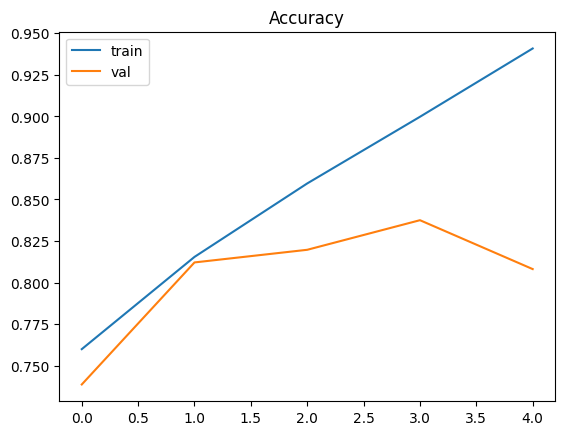

In [11]:
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.title("Accuracy")
plt.show()

# 10. Prediction

'test.jpg' not found. Selecting a random sample image from the dataset for testing...
Testing model using image: data/PetImages/Dog/4858.jpg


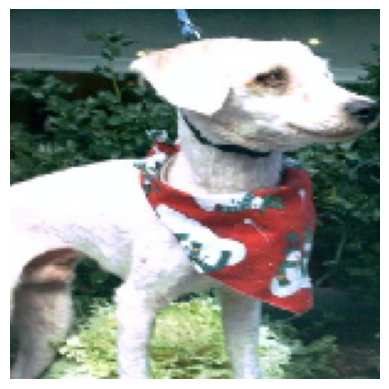

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
Dog 🐶 (99.68% probability)


In [13]:
from tensorflow.keras.preprocessing import image
import os
import random

# Automatically pick a test image from the dataset if 'test.jpg' does not exist
img_path = "test.jpg"

if not os.path.exists(img_path):
    print(f"'{img_path}' not found. Selecting a random sample image from the dataset for testing...")
    # Walk the directory to find a random image
    all_images = []
    for root, dirs, files in os.walk(data_dir):
        for file in files:
            if file.lower().endswith(('.png', '.jpg', '.jpeg')):
                all_images.append(os.path.join(root, file))
    if all_images:
        img_path = random.choice(all_images)
        print(f"Testing model using image: {img_path}")
    else:
        raise FileNotFoundError("No images found in the dataset folder to use as a fallback.")

# Load and preprocess the image
img = image.load_img(img_path, target_size=(150,150))
img_array = image.img_to_array(img)/255.0
img_array = np.expand_dims(img_array, axis=0)

# Display the image
plt.imshow(img)
plt.axis('off')
plt.show()

# Run prediction
prediction = model.predict(img_array)

# Display output
if prediction[0][0] > 0.5:
    print(f"Dog 🐶 ({prediction[0][0]*100:.2f}% probability)")
else:
    print(f"Cat 🐱 ({(1 - prediction[0][0])*100:.2f}% probability)")

# 📌 Project Summary

This project focuses on building a Convolutional Neural Network (CNN) model to classify images as either cats or dogs. The objective is to automate image classification using deep learning techniques.

The dataset consists of two categories: cats and dogs, stored in separate directories. The images are preprocessed by resizing and normalizing pixel values. Data augmentation is used to improve model performance.

A CNN model is built using TensorFlow and Keras, consisting of convolutional, pooling, and dense layers. The model is trained on the dataset and evaluated using accuracy metrics.

The results show that CNN models can effectively distinguish between cats and dogs. This project demonstrates the application of deep learning in image classification and can be extended to more complex problems.
